# Taxis NYC: Una app para quien toma decisiones

Pronóstico con incertidumbre, segmentación de zonas y una recomendación de cuántos taxis enviar, en una app de Streamlit que consulta su propia API.


In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

URL_VIAJES = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
URL_ZONAS  = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

os.makedirs("api", exist_ok=True)
os.makedirs("app/data", exist_ok=True)

## 1. Los Datos y las reglas comunes

 Para que los datos sean comparables se siguen las siguientes reglas:



Viajes válidos : Hora de inicio dentro de enero de 2024

Zona de un viaje : La de origen: PULocationID

Zonas que se pronostican:  Las que tienen al menos 3,000 viajes en el mes (sin las zonas "Unknown")

Zonas que se segmentan:  Las que tienen al menos 500 viajes en el mes (sin las zonas "Unknown")

Entrenamiento del pronóstico: Hasta el 24 de enero, inclusive

Prueba: Del 25 al 31 de enero

Pronóstico a futuro: El 1 de febrero, el "mañana": no tiene datos reales


In [2]:
cols = ["tpep_pickup_datetime", "PULocationID", "trip_distance", "fare_amount", "tip_amount"]
viajes = pd.read_parquet(URL_VIAJES, columns=cols)
zonas = pd.read_csv(URL_ZONAS)

# Verificar los viajes que si son válidos: hora de inicio dentro de enero de 2024
viajes = viajes[(viajes["tpep_pickup_datetime"] >= "2024-01-01") &
                (viajes["tpep_pickup_datetime"] <  "2024-02-01")].copy()
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")
print("Viajes válidos:", len(viajes))

Viajes válidos: 2964606


In [3]:
# Zonas "Unknown" (borough Unknown o vacío; pandas lee "N/A" como vacío)
ids_unknown = zonas.loc[zonas["Borough"].isna() | zonas["Borough"].isin(["Unknown"]) |
                        zonas["Zone"].isin(["Unknown", "Outside of NYC"]), "LocationID"]

conteo = viajes["PULocationID"].value_counts()
conteo = conteo[~conteo.index.isin(ids_unknown)]

zonas_pron = sorted(conteo[conteo >= 3000].index)   # se pronostican
zonas_seg  = sorted(conteo[conteo >= 500].index)    # se segmentan
print("Zonas a pronosticar (>=3000):", len(zonas_pron))
print("Zonas a segmentar  (>=500): ", len(zonas_seg))

Zonas a pronosticar (>=3000): 58
Zonas a segmentar  (>=500):  100


## 2. De viajes a serie de tiempo horaria
Se cuentan viajes por zona y hora, se rellenan con 0 las horas sin viajes y se agregan las 24 horas del **1 de febrero** (el "mañana", sin datos reales).

In [4]:
horas = pd.date_range("2024-01-01", "2024-02-01 23:00", freq="h")
idx = pd.MultiIndex.from_product([zonas_pron, horas], names=["PULocationID", "hora"])

serie = (viajes[viajes["PULocationID"].isin(zonas_pron)]
         .groupby(["PULocationID", "hora"]).size()
         .reindex(idx, fill_value=0).rename("viajes").reset_index())

# El 1 de febrero no tiene datos reales
serie.loc[serie["hora"] >= "2024-02-01", "viajes"] = np.nan

# Lags (ninguno menor a 24 h: el pronóstico se hace el día anterior)
g = serie.groupby("PULocationID")["viajes"]
for k in (24, 48, 167, 168, 169):
    serie[f"lag_{k}"] = g.shift(k)

# Promedio de viajes por hora del día anterior (día calendario completo)
serie["fecha"] = serie["hora"].dt.normalize()
diaria = serie.groupby(["PULocationID", "fecha"])["viajes"].mean().reset_index()
diaria["fecha"] = diaria["fecha"] + pd.Timedelta(days=1)
diaria = diaria.rename(columns={"viajes": "media_dia_ant"})
serie = serie.merge(diaria, on=["PULocationID", "fecha"], how="left")

# Calendario
serie["hora_dia"] = serie["hora"].dt.hour
serie["dia_semana"] = serie["hora"].dt.dayofweek
serie["feriado"] = (serie["fecha"] == "2024-01-15").astype(int)

# Zona como categoría nativa de XGBoost (guardamos las categorías para la API)
CATS = [int(z) for z in zonas_pron]
serie["zona"] = pd.Categorical(serie["PULocationID"], categories=CATS)

VARIABLES_NUM = ["lag_24", "lag_48", "lag_167", "lag_168", "lag_169",
                 "media_dia_ant", "hora_dia", "dia_semana", "feriado"]
VARIABLES = VARIABLES_NUM + ["zona"]
serie.head()

,PULocationID,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,fecha,media_dia_ant,hora_dia,dia_semana,feriado,zona
0,4,2024-01-01 00:00:00,25.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,0,0,0,4
1,4,2024-01-01 01:00:00,29.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,1,0,0,4
2,4,2024-01-01 02:00:00,34.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,2,0,0,4
3,4,2024-01-01 03:00:00,31.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,3,0,0,4
4,4,2024-01-01 04:00:00,32.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,4,0,0,4


## 3. Parte 1 · Modelo de cuantiles evaluado por tiempo
Entrena hasta el 24 de enero, prueba del 25 al 31, pronóstico a futuro el 1 de febrero. **Nunca `train_test_split`.**

In [5]:
entrena = serie[serie["hora"] < "2024-01-25"].dropna(subset=["lag_24", "lag_48", "lag_167", "lag_168", "lag_169", "media_dia_ant"])
prueba  = serie[(serie["hora"] >= "2024-01-25") & (serie["hora"] < "2024-02-01")].copy()
futuro  = serie[serie["hora"] >= "2024-02-01"].copy()
print(len(entrena), len(prueba), len(futuro))

CUANTILES = np.round(np.arange(0.1, 0.91, 0.1), 1)
NOMBRES_Q = [f"p{int(round(q*100))}" for q in CUANTILES]

modelo = XGBRegressor(objective="reg:quantileerror", quantile_alpha=CUANTILES,
                      tree_method="hist", enable_categorical=True,
                      n_estimators=250, max_depth=5, learning_rate=0.05, random_state=42)
modelo.fit(entrena[VARIABLES], entrena["viajes"])

def predecir(df):
    p = modelo.predict(df[VARIABLES])
    p = np.sort(p, axis=1)          # para evitar cuantiles cruzados
    return np.clip(p, 0, None)

23606 9744 1392


In [6]:
pp = predecir(prueba)
for i, nombre in enumerate(NOMBRES_Q):
    prueba[nombre] = pp[:, i]

mae = lambda a, b: float(np.mean(np.abs(a - b)))
mae_modelo = mae(prueba["viajes"], prueba["p50"])
mae_semana = mae(prueba["viajes"], prueba["lag_168"])   # regla: Viajes igual que hace una semana
mae_ayer   = mae(prueba["viajes"], prueba["lag_24"])    # regla: Viajes igual que ayer
cobertura  = float(((prueba["viajes"] >= prueba["p10"]) & (prueba["viajes"] <= prueba["p90"])).mean())

print(f"Error del modelo (mediana):       {mae_modelo:.2f} viajes/hora")
print(f"Regla 'igual que hace una semana': {mae_semana:.2f}")
print(f"Regla 'igual que ayer':            {mae_ayer:.2f}")
print(f"Cobertura del rango 10%-90%:       {cobertura:.1%}  (objetivo 80%)")
print(f"Horas-zona evaluadas:              {len(prueba)}")

Error del modelo (mediana):       12.06 viajes/hora
Regla 'igual que hace una semana': 11.88
Regla 'igual que ayer':            21.29
Cobertura del rango 10%-90%:       89.7%  (objetivo 80%)
Horas-zona evaluadas:              9744


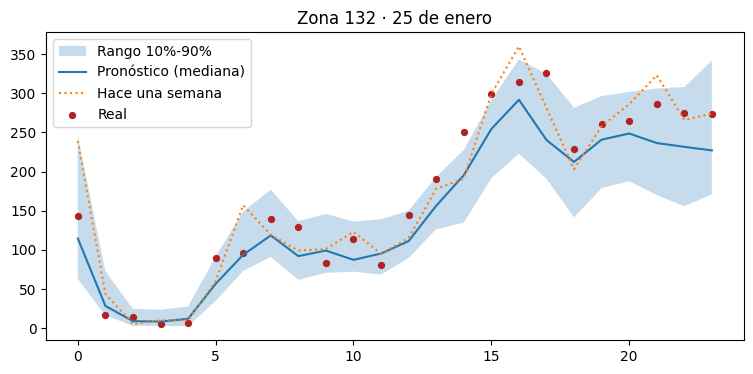

In [7]:
# Vista rápida de una zona (la de más viajes) un día de la semana de prueba
z = conteo.index[0]
d = prueba[(prueba["PULocationID"] == z) & (prueba["hora"].dt.date == pd.Timestamp("2024-01-25").date())]
plt.figure(figsize=(9, 4))
plt.fill_between(d["hora_dia"], d["p10"], d["p90"], alpha=0.25, label="Rango 10%-90%")
plt.plot(d["hora_dia"], d["p50"], label="Pronóstico (mediana)")
plt.plot(d["hora_dia"], d["lag_168"], ":", label="Hace una semana")
plt.scatter(d["hora_dia"], d["viajes"], c="firebrick", s=18, label="Real")
plt.title(f"Zona {z} · 25 de enero"); plt.legend(); plt.show()

## 4. Parte 2 · Segmentación de zonas (K-Means + PCA)
Una fila por zona (>= 500 viajes). Variables escaladas con `StandardScaler`; k se justifica con el coeficiente de silueta (k = 2 a 7).

In [8]:
v = viajes[viajes["PULocationID"].isin(zonas_seg)].copy()
v["hh"] = v["tpep_pickup_datetime"].dt.hour
v["finde"] = v["tpep_pickup_datetime"].dt.dayofweek >= 5

pz = v.groupby("PULocationID")
feat = pd.DataFrame({
    "viajes_dia": pz.size() / 31,
    "pct_finde":  pz["finde"].mean(),
    "pct_6_10":   pz["hh"].apply(lambda s: s.between(6, 10).mean()),
    "pct_16_20":  pz["hh"].apply(lambda s: s.between(16, 20).mean()),
    "pct_22_5":   pz["hh"].apply(lambda s: ((s >= 22) | (s <= 5)).mean()),
})

# Distancia, tarifa y propina: primero se descartan viajes con distancia o tarifa <= 0
vd = v[(v["trip_distance"] > 0) & (v["fare_amount"] > 0)].groupby("PULocationID")
feat["dist_mediana"]    = vd["trip_distance"].median()
feat["tarifa_mediana"]  = vd["fare_amount"].median()
feat["propina_mediana"] = vd["tip_amount"].median()
feat["viajes_dia_log"]  = np.log10(feat["viajes_dia"])      # hay zonas con 30 y otras con 4,500
feat = feat.dropna()

FEATS = ["viajes_dia_log", "dist_mediana", "tarifa_mediana", "propina_mediana",
         "pct_finde", "pct_6_10", "pct_16_20", "pct_22_5"]

# Perfil horario (proporción de viajes por hora, 0 a 23) para el gráfico de la app
perfil = v.groupby(["PULocationID", "hh"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
perfil = perfil.div(perfil.sum(axis=1), axis=0).loc[feat.index]

X = StandardScaler().fit_transform(feat[FEATS])
print(feat.shape)

(100, 9)


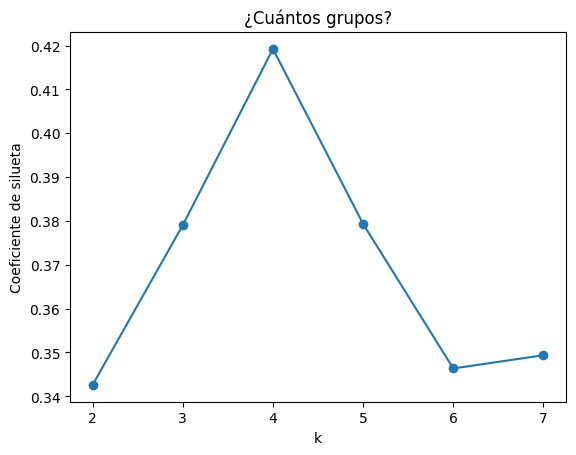

{2: np.float64(0.343), 3: np.float64(0.379), 4: np.float64(0.419), 5: np.float64(0.379), 6: np.float64(0.346), 7: np.float64(0.349)}
k elegido: 4


In [9]:
silueta = {}
for k in range(2, 8):
    etiquetas = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    silueta[k] = silhouette_score(X, etiquetas)

plt.plot(list(silueta), list(silueta.values()), marker="o")
plt.xlabel("k"); plt.ylabel("Coeficiente de silueta"); plt.title("¿Cuántos grupos?"); plt.show()
print({k: round(s, 3) for k, s in silueta.items()})

# Se elige el k con mayor silueta. Si k=2 gana por poco, pueden elegir 3 o 4 y
# justificarlo en la ficha (más útil para operaciones), siempre mostrando este gráfico.
K = max(silueta, key=silueta.get)
print("k elegido:", K)

In [10]:
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
feat["grupo"] = km.labels_

pca = PCA(n_components=2, random_state=42)
comp = pca.fit_transform(X)
feat["pc1"], feat["pc2"] = comp[:, 0], comp[:, 1]
var_pca = float(pca.explained_variance_ratio_.sum())
print(f"PCA conserva {var_pca:.1%} de la variación")

# Nombres según el PERFIL del grupo (no a mano por número):
# se toma la variable en la que el centro del grupo más se aleja del promedio.
centros = pd.DataFrame(X, columns=FEATS, index=feat.index).groupby(feat["grupo"]).mean()
ETIQ = {("dist_mediana", 1): "Viajes largos y aeropuertos", ("tarifa_mediana", 1): "Tarifas altas",
        ("propina_mediana", 1): "Propinas altas", ("pct_22_5", 1): "Vida nocturna",
        ("viajes_dia_log", 1): "Alta demanda", ("viajes_dia_log", -1): "Barrios periféricos",
        ("pct_finde", 1): "Fin de semana", ("pct_6_10", 1): "Pico de mañana",
        ("pct_16_20", 1): "Pico de tarde"}
usados, nombres, descr = set(), {}, {}
for gr in centros.index:
    orden = centros.loc[gr].abs().sort_values(ascending=False).index
    for f in orden:
        signo = 1 if centros.loc[gr, f] > 0 else -1
        n = ETIQ.get((f, signo), f"{f} {'alto' if signo > 0 else 'bajo'}")
        if n not in usados:
            break
    usados.add(n); nombres[gr] = n
    top2 = [f"{f} {'alto' if centros.loc[gr, f] > 0 else 'bajo'}" for f in orden[:2]]
    descr[gr] = "Se distingue por: " + ", ".join(top2)
feat["nombre_grupo"] = feat["grupo"].map(nombres)
feat["descripcion"] = feat["grupo"].map(descr)

# Revisen este resumen y, si un nombre no tiene sentido, ajusten el diccionario ETIQ (no el número del grupo)
resumen = feat.groupby("nombre_grupo").agg(zonas=("viajes_dia", "size"), viajes_dia=("viajes_dia", "mean"),
          dist_mediana=("dist_mediana", "median"), pct_noche=("pct_22_5", "mean"), descripcion=("descripcion", "first"))
resumen

PCA conserva 64.8% de la variación


,zonas,viajes_dia,dist_mediana,pct_noche,descripcion
nombre_grupo,,,,,
Barrios periféricos,37,43.419355,3.830,0.188433,"Se distingue por: viajes_dia_log bajo, pct_6_1..."
Pico de tarde,46,1662.246844,1.605,0.135993,"Se distingue por: pct_16_20 alto, viajes_dia_l..."
Propinas altas,5,1603.638710,9.490,0.188308,"Se distingue por: propina_mediana alto, tarifa..."
Vida nocturna,12,700.196237,2.090,0.494721,"Se distingue por: pct_22_5 alto, pct_finde alto"


In [11]:
seg = feat.reset_index().rename(columns={"PULocationID": "zona_id"})
seg = seg.merge(zonas.rename(columns={"LocationID": "zona_id", "Zone": "zona", "Borough": "distrito"})[["zona_id", "zona", "distrito"]],
                on="zona_id", how="left")
perfil_cols = perfil.copy(); perfil_cols.columns = [f"h{h:02d}" for h in range(24)]
seg = seg.merge(perfil_cols.reset_index().rename(columns={"PULocationID": "zona_id"}), on="zona_id")
seg.to_csv("app/data/zonas_segmentadas.csv", index=False)

pd.DataFrame({"k": list(silueta), "silueta": list(silueta.values())}).to_csv("app/data/silueta.csv", index=False)
seg[["zona_id", "zona", "distrito", "nombre_grupo", "viajes_dia", "pc1", "pc2"]].head()

,zona_id,zona,distrito,nombre_grupo,viajes_dia,pc1,pc2
0,4,Alphabet City,Manhattan,Vida nocturna,115.096774,0.069582,4.640281
1,7,Astoria,Queens,Barrios periféricos,58.419355,-0.994756,0.490511
2,10,Baisley Park,Queens,Propinas altas,32.225806,-2.851427,-0.485588
3,12,Battery Park,Manhattan,Pico de tarde,28.225806,0.161490,-0.375264
4,13,Battery Park City,Manhattan,Pico de tarde,512.161290,1.556726,-1.766726


## 5. Parte 4 · Errores por tipo de zona y cobertura
Aquí se unen el pronóstico (Parte 1) y los grupos (Parte 2).

In [12]:
prueba["error_modelo"] = (prueba["viajes"] - prueba["p50"]).abs()
prueba["error_semana"] = (prueba["viajes"] - prueba["lag_168"]).abs()
prueba["dentro"] = ((prueba["viajes"] >= prueba["p10"]) & (prueba["viajes"] <= prueba["p90"])).astype(float)

pg = prueba.merge(seg[["zona_id", "nombre_grupo"]], left_on="PULocationID", right_on="zona_id", how="left")
por_grupo = pg.groupby("nombre_grupo").agg(zonas=("PULocationID", "nunique"),
                                           mae_modelo=("error_modelo", "mean"),
                                           mae_semana=("error_semana", "mean"),
                                           cobertura=("dentro", "mean")).round(3)
por_zona_cob = prueba.groupby("PULocationID")["dentro"].mean()
print(f"Cobertura por zona: mínimo {por_zona_cob.min():.0%}, máximo {por_zona_cob.max():.0%}")
por_grupo

Cobertura por zona: mínimo 78%, máximo 97%


,zonas,mae_modelo,mae_semana,cobertura
nombre_grupo,,,,
Barrios periféricos,3,2.333,2.849,0.929
Pico de tarde,44,12.566,12.457,0.897
Propinas altas,3,19.006,20.056,0.869
Vida nocturna,8,10.316,9.042,0.898


## 6. Parte 3 · Costo de las decisiones (comprobación)
`cuantil óptimo = costo_perdido / (costo_perdido + costo_ocioso)`. Cada taxi cubre un viaje por hora.

In [13]:
def costo(enviados, real, c_ocioso, c_perdido):
    return float((np.maximum(enviados - real, 0) * c_ocioso + np.maximum(real - enviados, 0) * c_perdido).sum())

c_ocioso, c_perdido = 10, 40
q_opt = c_perdido / (c_perdido + c_ocioso)                          # 0.80
col_q = NOMBRES_Q[int(np.argmin(np.abs(CUANTILES - q_opt)))]        # se usa el cuantil disponible más cercano
print("Cuantil óptimo:", q_opt, "->", col_q)

r = prueba["viajes"]
print("Costo recomendación:  ", round(costo(prueba[col_q], r, c_ocioso, c_perdido)))
print("Costo pronóstico p50: ", round(costo(prueba["p50"], r, c_ocioso, c_perdido)))
print("Costo hace una semana:", round(costo(prueba["lag_168"], r, c_ocioso, c_perdido)))

Cuantil óptimo: 0.8 -> p80
Costo recomendación:   2309711
Costo pronóstico p50:  3308860
Costo hace una semana: 3160950


## 7. Extra · Monitoreo día a día (+10)
Error por día de la semana de prueba y un límite definido por ustedes.

In [14]:
prueba["dia"] = prueba["hora"].dt.date
monitoreo = prueba.groupby("dia").agg(mae_modelo=("error_modelo", "mean"), mae_semana=("error_semana", "mean"),
                                      cobertura=("dentro", "mean")).round(3).reset_index()
LIMITE_MAE = round(mae_modelo * 1.25, 2)     # ejemplo: alerta si el error supera 25% del error medio. Defínanlo ustedes.
monitoreo["alerta"] = monitoreo["mae_modelo"] > LIMITE_MAE
monitoreo.to_csv("app/data/monitoreo.csv", index=False)
print("Límite:", LIMITE_MAE)
monitoreo

Límite: 15.07


,dia,mae_modelo,mae_semana,cobertura,alerta
0,2024-01-25,10.505,11.524,0.920,False
1,2024-01-26,11.020,12.590,0.927,False
2,2024-01-27,15.077,15.400,0.861,True
3,2024-01-28,14.278,13.564,0.867,False
4,2024-01-29,13.545,8.766,0.885,False
5,2024-01-30,10.363,10.801,0.904,False
6,2024-01-31,9.628,10.527,0.916,False


## 8. Exportar para la API y la app
- `api/modelo_pronostico.ubj`, `api/config_modelo.json`, `api/demanda.parquet`, `api/zonas.csv`
- `app/data/metricas.json` (cifras de la ficha), `zonas_segmentadas.csv`, `silueta.csv`, `monitoreo.csv`

In [15]:
modelo.save_model("api/modelo_pronostico.ubj")
json.dump({"categorias_zona": CATS, "variables": VARIABLES, "cuantiles": [float(q) for q in CUANTILES]},
          open("api/config_modelo.json", "w"))

#s (la API no recalcula lags)
demanda = serie[serie["hora"] >= "2024-01-25"][["PULocationID", "hora", "viajes"] + VARIABLES_NUM].copy()
demanda.to_parquet("api/demanda.parquet", index=False)

zonas[zonas["LocationID"].isin(zonas_pron)][["LocationID", "Zone", "Borough"]].to_csv("api/zonas.csv", index=False)

metricas = {
    "mae_modelo": mae_modelo, "mae_semana": mae_semana, "mae_ayer": mae_ayer,
    "cobertura_80": cobertura, "horas_zona_prueba": int(len(prueba)),
    "zonas_pronosticadas": len(zonas_pron), "zonas_segmentadas": len(zonas_seg),
    "k": int(K), "silueta_k": float(silueta[K]), "varianza_pca": var_pca,
    "cobertura_zona_min": float(por_zona_cob.min()), "cobertura_zona_max": float(por_zona_cob.max()),
    "por_grupo": por_grupo.reset_index().to_dict(orient="records"),
    "limite_monitoreo": LIMITE_MAE,
}
json.dump(metricas, open("app/data/metricas.json", "w"), indent=2, default=float)
print(json.dumps({k: v for k, v in metricas.items() if k != "por_grupo"}, indent=2, default=float))
print(os.listdir("api"), os.listdir("app/data"))

{
  "mae_modelo": 12.059543995227212,
  "mae_semana": 11.881773399014778,
  "mae_ayer": 21.286330049261085,
  "cobertura_80": 0.8973727422003284,
  "horas_zona_prueba": 9744,
  "zonas_pronosticadas": 58,
  "zonas_segmentadas": 100,
  "k": 4,
  "silueta_k": 0.4192222505368944,
  "varianza_pca": 0.6484711633555893,
  "cobertura_zona_min": 0.7797619047619048,
  "cobertura_zona_max": 0.9702380952380952,
  "limite_monitoreo": 15.07
}
['demanda.parquet', 'config_modelo.json', 'modelo_pronostico.ubj', '__pycache__', 'requirements.txt', 'zonas.csv', 'main.py'] ['monitoreo.csv', 'zonas_segmentadas.csv', 'silueta.csv', 'metricas.json']


In [16]:
!nohup uvicorn main:app --host 0.0.0.0 --port 8000 > servidor.log 2>&1 & echo $! > servidor.pid

In [17]:
%%writefile api/main.py
import json
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from xgboost import XGBRegressor

BASE = Path(__file__).parent

config = json.loads((BASE / "config_modelo.json").read_text(encoding="utf-8"))
VARIABLES = config["variables"]
CATEGORIAS = config["categorias_zona"]
NOMBRES_Q = [f"p{int(round(q * 100))}" for q in config["cuantiles"]]

modelo = XGBRegressor(enable_categorical=True)
modelo.load_model(BASE / "modelo_pronostico.ubj")

demanda = pd.read_parquet(BASE / "demanda.parquet")
zonas = pd.read_csv(BASE / "zonas.csv").set_index("LocationID")
FECHAS = sorted(demanda["hora"].dt.date.unique())

app = FastAPI(title="Taxis NYC · API de pronóstico")


def _numero(x):
    return None if pd.isna(x) else int(x)


@app.get("/")
def raiz():
    return {"estado": "en línea", "mensaje": "Abre /docs para probar los endpoints"}


@app.get("/info")
def info():
    ids = [z for z in zonas.index if z in set(demanda["PULocationID"])]
    lista = [{"id": int(z), "nombre": zonas.loc[z, "Zone"], "distrito": zonas.loc[z, "Borough"]} for z in ids]
    lista.sort(key=lambda z: z["nombre"])
    return {"zonas": lista, "fechas": [f.isoformat() for f in FECHAS], "cuantiles": NOMBRES_Q}


@app.get("/pronostico")
def pronostico(zona_id: int, fecha: date):
    filas = demanda[(demanda["PULocationID"] == zona_id) & (demanda["hora"].dt.date == fecha)]
    if filas.empty:
        raise HTTPException(status_code=404, detail="No hay datos para esa zona o fecha")
    filas = filas.sort_values("hora").copy()
    filas["zona"] = pd.Categorical(filas["PULocationID"], categories=CATEGORIAS)

    pred = modelo.predict(filas[VARIABLES])
    pred = np.clip(np.sort(pred, axis=1), 0, None)

    horas = []
    for i, (_, fila) in enumerate(filas.iterrows()):
        horas.append({
            "hora": int(fila["hora"].hour),
            "real": _numero(fila["viajes"]),
            "hace_una_semana": _numero(fila["lag_168"]),
            "cuantiles": {n: round(float(pred[i, j]), 1) for j, n in enumerate(NOMBRES_Q)},
        })
    return {
        "zona": {"id": zona_id, "nombre": zonas.loc[zona_id, "Zone"], "distrito": zonas.loc[zona_id, "Borough"]},
        "fecha": fecha.isoformat(),
        "horas": horas,
    }

Overwriting api/main.py


In [18]:
%%writefile api/requirements.txt
pandas
numpy
matplotlib
scikit-learn
xgboost==3.4.1
plotly
pyarrow
fastapi
uvicorn
requests
streamlit

Overwriting api/requirements.txt


In [19]:
!ls api

config_modelo.json  main.py		   __pycache__	     zonas.csv
demanda.parquet     modelo_pronostico.ubj  requirements.txt


In [20]:
!pip -q install fastapi uvicorn
!pkill -f uvicorn
!nohup uvicorn main:app --app-dir api --host 0.0.0.0 --port 8000 > servidor.log 2>&1 &

import time, requests
time.sleep(10)                      # darle tiempo a cargar el modelo
!cat servidor.log

print(requests.get("http://localhost:8000/").json())
r = requests.get("http://localhost:8000/pronostico", params={"zona_id": 161, "fecha": "2024-01-25"})
print(r.status_code, r.json()["horas"][17])
r = requests.get("http://localhost:8000/pronostico", params={"zona_id": 99999, "fecha": "2024-01-25"})
print(r.status_code, r.json())

INFO:     Started server process [1831]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
{'estado': 'en línea', 'mensaje': 'Abre /docs para probar los endpoints'}
200 {'hora': 17, 'real': 580, 'hace_una_semana': 623, 'cuantiles': {'p10': 335.8, 'p20': 440.5, 'p30': 465.2, 'p40': 466.3, 'p50': 498.1, 'p60': 536.8, 'p70': 563.7, 'p80': 588.0, 'p90': 619.4}}
404 {'detail': 'No hay datos para esa zona o fecha'}


In [21]:
from google.colab import output
output.serve_kernel_port_as_window(8000, path="/docs")

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>